# Experiments Behind the Model Choice: Subset Runs and Full-Data Models

**Sujal Patnaik (roll no. 240150041); Kushagra Singhal (roll no. 240150046); Sudipto Ghosh (roll no. 240150042)**

**Course: DA-331 | November 2026**

This notebook provides the evidence for the experiments that are not covered in the main notebook (`EmoLDGN_BRIGHTER.ipynb`):

| Part | Contents |
|---|---|
| 1 | Setup and how the results are obtained |
| 2 | Availability of the stored results |
| 3 | Scoring of all runs |
| 4 | The subset experiment: 17 runs on four languages, used to decide which additions to keep |
| 5 | Full-data comparison: `final_full` and `final_full_noquota`, with `b4_full` and `best_full` as references |
| 6 | Conclusions |

**Data.** All results are computed on BRIGHTER (SemEval-2025 Task 11) only. BRIGHTER is used for research, and this notebook never prints the text of a row.

**Models compared.**

| Name | Contents |
|---|---|
| B2 | XLM-RoBERTa with mean pooling and a linear head (no graph) |
| B4 | LDGN on XLM-RoBERTa, with no additions |
| N1 | B4 with label anchors |
| N2 | B4 with the signed graph and neutral node |
| N4 | B4 with the hierarchical graph prior |
| N5 | B4 with the graph regulariser and gate |
| N6 | B4 with the ordinal intensity head |
| `final_full` | all five additions (N1, N2, N4, N5, N6) with the intensity quota |
| `final_full_noquota` | all five additions without the quota |

## 1. Setup

**How the results are obtained.** For every run, the notebook first looks for the stored prediction files in `runs/<run>/predictions/`.

| Situation | What happens | Time |
|---|---|---|
| **All stored prediction files are found** (the default case when the project files or the Drive bundle, part 3, are present) | The results are computed directly from the stored predictions. No model is loaded and no GPU is used. | about 5 minutes |
| **Some files are missing** | The missing runs are produced here: the data tables are rebuilt if necessary, the model is trained (or its saved weights are scored), and the predictions are written. | up to about 5 hours for all 19 runs on a 4 GB GPU |
| `FORCE_RETRAIN = True` | The runs are trained again even if predictions exist. This overwrites the stored runs and is intended only for a full reproduction. | up to about 5 hours |

**Requirements for the stored-results route.** Python with `numpy`, `pandas`, `matplotlib`, `seaborn`, `pyyaml` and `scikit-learn`, and the files from the Drive bundle (part 3) restored with `scripts/restore_from_drive.py`. The training route additionally requires Java for Spark, the raw BRIGHTER files, a CUDA GPU of at least 4 GB, and the packages in `requirements.txt`.

**Time for the training route (RTX 3050, 4 GB).**

| Runs | Time |
|---|---|
| 17 subset runs (7 to 9 minutes each) and their scoring | about 3 hours 10 minutes |
| `final_full` (5 epochs) and its scoring | about 40 minutes |
| `final_full_noquota` (8 epochs) and its scoring | about 55 minutes |

In [1]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import Markdown, display

FORCE_RETRAIN = False        # True: train the runs again even if predictions exist (overwrites the stored runs)
TRAIN_IF_MISSING = True      # False: never train; report missing runs instead
ALLOW_CPU_TRAINING = False   # training without a CUDA GPU takes days; it is refused unless this is True

ROOT = Path.cwd()
assert (ROOT / "emoldgn").is_dir(), "The notebook must be started from the repository root."
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "figure.autolayout": True})
TEAL, CORAL, SLATE, MINT = "#0F766E", "#D9534F", "#64748B", "#9BCBC4"


def markdown_table(frame, max_rows=80):
    # Tables are shown as Markdown, which every notebook viewer and GitHub renders.
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()

    def cell(v):
        if isinstance(v, (float, np.floating)):
            if np.isnan(v):
                return ""
            if abs(v) < 1:
                return f"{v:.3f}"
            text = f"{v:,.3f}"
            return text[:-1] if text.endswith("0") else text
        return str(v).replace("|", "\\|")

    shown = frame.head(max_rows)
    lines = ["| " + " | ".join([str(frame.index.name or "")] + [str(c) for c in frame.columns]) + " |",
             "|" + "---|" * (frame.shape[1] + 1)]
    lines += ["| " + " | ".join([cell(i)] + [cell(v) for v in row]) + " |" for i, row in zip(shown.index, shown.values)]
    return "\n".join(lines)


pd.set_option("display.notebook_repr_html", False)
_fmt = get_ipython().display_formatter.formatters["text/markdown"]
_fmt.for_type(pd.DataFrame, markdown_table)
_fmt.for_type(pd.Series, markdown_table)


def say(text):
    display(Markdown(text))

## 2. The runs and the availability of their results

The runs are defined in `config/experiments.yaml`. The table lists every run used in this notebook with its data, seed and additions.

In [2]:
with open(ROOT / "config/experiments.yaml", encoding="utf-8") as f:
    DEFS = {e["id"]: e for e in yaml.safe_load(f)["experiments"]}

SUBSET = ["b2_subset", "b4_subset_s42", "s1_subset", "s2_subset", "final_subset_s42", "b4_subset_s1", "b4_subset_s2",
          "final_subset_s1", "final_subset_s2", "nq_subset_s42", "nq_subset_s1", "nq_subset_s2",
          "a_n1_subset", "a_n2_subset", "a_n4_subset", "a_n5_subset", "a_n6_subset"]
FULL = ["final_full", "final_full_noquota"]
REFERENCE = ["b4_full", "best_full"]          # used for comparison only; never trained by this notebook
REQUIRED = SUBSET + FULL

NAMES = {"n1_anchors": "N1", "n2_signed": "N2", "n4_hierarchical": "N4", "n5_reg_gate": "N5", "n6_intensity": "N6"}


def describe(run):
    e = DEFS[run]
    flags = e["flags"]
    if flags.get("head") == "linear":
        adds = "linear head"
    else:
        adds = " + ".join(v for k, v in NAMES.items() if flags.get(k)) or "none (B4)"
    quota = "n/a" if not flags.get("n6_intensity") else ("no" if e.get("intensity_quota") is False else "yes")
    return {"data": "4 languages" if e["data"] == "subset" else "28 languages", "seed": e["seed"],
            "additions": adds, "intensity quota": quota}


registry = pd.DataFrame({r: describe(r) for r in REQUIRED + REFERENCE}).T
registry.index.name = "run"
registry

| run | data | seed | additions | intensity quota |
|---|---|---|---|---|
| b2_subset | 4 languages | 42 | linear head | n/a |
| b4_subset_s42 | 4 languages | 42 | none (B4) | n/a |
| s1_subset | 4 languages | 42 | N1 + N2 | n/a |
| s2_subset | 4 languages | 42 | N1 + N2 + N4 + N5 | n/a |
| final_subset_s42 | 4 languages | 42 | N1 + N2 + N4 + N5 + N6 | yes |
| b4_subset_s1 | 4 languages | 1 | none (B4) | n/a |
| b4_subset_s2 | 4 languages | 2 | none (B4) | n/a |
| final_subset_s1 | 4 languages | 1 | N1 + N2 + N4 + N5 + N6 | yes |
| final_subset_s2 | 4 languages | 2 | N1 + N2 + N4 + N5 + N6 | yes |
| nq_subset_s42 | 4 languages | 42 | N1 + N2 + N4 + N5 + N6 | no |
| nq_subset_s1 | 4 languages | 1 | N1 + N2 + N4 + N5 + N6 | no |
| nq_subset_s2 | 4 languages | 2 | N1 + N2 + N4 + N5 + N6 | no |
| a_n1_subset | 4 languages | 42 | N1 | n/a |
| a_n2_subset | 4 languages | 42 | N2 | n/a |
| a_n4_subset | 4 languages | 42 | N4 | n/a |
| a_n5_subset | 4 languages | 42 | N5 | n/a |
| a_n6_subset | 4 languages | 42 | N6 | no |
| final_full | 28 languages | 42 | N1 + N2 + N4 + N5 + N6 | yes |
| final_full_noquota | 28 languages | 42 | N1 + N2 + N4 + N5 + N6 | no |
| b4_full | 28 languages | 42 | none (B4) | n/a |
| best_full | 28 languages | 42 | N6 | no |

**Interpretation.** The 17 subset runs use four languages (English, Hausa, Marathi and Ukrainian), which makes each run short enough (7 to 9 minutes) to compare many variants. They contain each addition on its own, cumulative combinations, and three seeds for B4, for all additions and for all additions without the quota. The two full-data runs use all 28 languages. The intensity quota is a sampling rule that drew about half of each batch from the 11 languages with intensity labels, and it applies only where the intensity head (N6) is present.

In [3]:
def files_of(run):
    p = ROOT / "runs" / run / "predictions"
    need = ["val.npz", "test.npz"] + (["trackc.npz"] if run.startswith("final_full") or run == "best_full" else [])
    return {n: (p / n).exists() for n in need}


rows = {}
for r in REQUIRED + REFERENCE:
    found = files_of(r)
    rows[r] = {"validation": "found" if found["val.npz"] else "MISSING", "test": "found" if found["test.npz"] else "MISSING",
               "Track C": ("found" if found["trackc.npz"] else "MISSING") if "trackc.npz" in found else "not needed",
               "role": "required" if r in REQUIRED else "reference"}
availability = pd.DataFrame(rows).T
availability.index.name = "run"
missing = [r for r in REQUIRED if not all(files_of(r).values())]
absent_reference = [r for r in REFERENCE if not all(files_of(r).values())]
availability

| run | validation | test | Track C | role |
|---|---|---|---|---|
| b2_subset | found | found | not needed | required |
| b4_subset_s42 | found | found | not needed | required |
| s1_subset | found | found | not needed | required |
| s2_subset | found | found | not needed | required |
| final_subset_s42 | found | found | not needed | required |
| b4_subset_s1 | found | found | not needed | required |
| b4_subset_s2 | found | found | not needed | required |
| final_subset_s1 | found | found | not needed | required |
| final_subset_s2 | found | found | not needed | required |
| nq_subset_s42 | found | found | not needed | required |
| nq_subset_s1 | found | found | not needed | required |
| nq_subset_s2 | found | found | not needed | required |
| a_n1_subset | found | found | not needed | required |
| a_n2_subset | found | found | not needed | required |
| a_n4_subset | found | found | not needed | required |
| a_n5_subset | found | found | not needed | required |
| a_n6_subset | found | found | not needed | required |
| final_full | found | found | found | required |
| final_full_noquota | found | found | found | required |
| b4_full | found | found | not needed | reference |
| best_full | found | found | found | reference |

In [4]:
if FORCE_RETRAIN:
    missing = list(REQUIRED)
    say("**Route: training.** `FORCE_RETRAIN` is set, so all required runs will be trained again.")
elif not missing:
    say(f"**Route: stored results.** All prediction files of the {len(REQUIRED)} required runs were found, so the results below are computed from them directly. No training is performed.")
else:
    say(f"**Route: training for the missing runs.** {len(missing)} required runs have incomplete prediction files: {', '.join(missing)}.")
if absent_reference:
    say(f"The reference runs {', '.join(absent_reference)} are not available. They are used only for comparison and are left out of the tables.")

**Route: stored results.** All prediction files of the 19 required runs were found, so the results below are computed from them directly. No training is performed.

**Interpretation.** A prediction file contains, for every row of the validation or test split, the model's probabilities, the thresholded labels, the gold labels and (where present) the intensities. The tuned thresholds were chosen on validation only, and each model's test split was scored once, so the stored files carry exactly the information needed to recompute every score reported here.

### Producing missing runs

The next cell does nothing when all prediction files exist. If runs are missing, it performs the following steps for each of them:

1. If the data tables are missing, the Spark jobs 01 to 07 are run (about two minutes).
2. If no best checkpoint exists, the model is trained with `emoldgn.train` (checkpoint after every epoch, so an interrupted run resumes).
3. The thresholds are tuned on validation and the validation and test splits are scored with `emoldgn.predict`.

In [5]:
def ensure_tables():
    from spark_jobs.common import load_config, path_of
    cfg = load_config()
    if (Path(path_of(cfg, "gold", "tokenized")).exists() and Path(path_of(cfg, "gold", "graph_bank.pt")).exists()):
        return
    if not Path(path_of(cfg, "raw")).is_dir():
        raise FileNotFoundError("The raw BRIGHTER files are missing: run python scripts/download_data.py first.")
    for job in ("01_ingest", "02_clean", "03_split", "04_graphs", "06_priors", "07_tokenize"):
        print(f"running {job} ...")
        done = subprocess.run([sys.executable, str(ROOT / "spark_jobs" / f"{job}.py")], cwd=ROOT, capture_output=True, text=True)
        if done.returncode != 0:
            raise RuntimeError(f"{job} failed:\n{done.stdout[-800:]}\n{done.stderr[-800:]}")


def produce(exp):
    from emoldgn.predict import predict_run
    from emoldgn.train import resolve, run_with_retries
    from spark_jobs.common import path_of

    import torch

    cfg = resolve(exp)
    run = Path(path_of(cfg, "runs", exp))
    state = run / "status.json"
    finished = state.exists() and json.loads(state.read_text()).get("status") == "done" and (run / "ckpt_best.pt").exists()
    # A best checkpoint exists after the first epoch, so it only counts together with status "done".
    if FORCE_RETRAIN or not finished:
        if not torch.cuda.is_available() and not ALLOW_CPU_TRAINING:
            raise RuntimeError("No CUDA GPU was found. Training on a CPU takes days; set ALLOW_CPU_TRAINING = True to allow it, "
                               "or restore the stored prediction files (Drive part 3) instead.")
        ensure_tables()
        print(f"{exp}: training ...")
        resume = (run / "ckpt_last.pt").exists() and not FORCE_RETRAIN
        if FORCE_RETRAIN:
            for name in ("ckpt_last.pt", "ckpt_best.pt", "status.json"):
                (run / name).unlink(missing_ok=True)
        status = run_with_retries(cfg, run, resume, None)
        if status != "done":
            raise RuntimeError(f"{exp} ended with status {status!r}; executing this cell again resumes from the last saved epoch.")
    ensure_tables()
    print(f"{exp}: scoring ...")
    print(predict_run(exp, force=FORCE_RETRAIN))


if missing and not TRAIN_IF_MISSING:
    raise FileNotFoundError(f"Missing prediction files for: {missing}")
for exp in missing:
    produce(exp)
if missing:
    missing = [r for r in REQUIRED if not all(files_of(r).values())]
    assert not missing, f"Still missing after training: {missing}"
    say("All required runs are now available.")
else:
    say("No run needed to be produced: all stored prediction files were found.")

No run needed to be produced: all stored prediction files were found.

## 3. Scoring

All scores are percentage points unless stated. The metrics follow the official definitions: macro-F1 per language over the emotions the language has, averaged over languages (Tracks A and C), and Pearson correlation per emotion and language, averaged (Track B). Thresholds are the validation-tuned values stored with each run.

In [6]:
from emoldgn import evaluate as E

def load(run, split):
    d = dict(np.load(ROOT / "runs" / run / "predictions" / f"{split}.npz", allow_pickle=True))
    order = np.argsort(d["id"], kind="stable")
    return {k: v[order] if getattr(v, "ndim", 0) >= 1 and len(v) == len(order) else v for k, v in d.items()}


def summarise(run):
    out = {"run": run}
    for split in ("val", "test"):
        d = load(run, split)
        a = E.track_a(d["y"], d["pred"], d["mask"], d["lang"])
        out[f"{split}_f1"] = a["mean"] * 100
        out[f"{split}_lang"] = {k: v * 100 for k, v in a["per_language"].items()}
        if split == "test":
            out["fidelity"] = E.cooccurrence_fidelity(d["y"], d["pred"], d["mask"], d["lang"])
            out["ece"] = E.ece(d["p"][:, :6], d["y"], d["mask"])
            out["emotion"] = {k: v * 100 for k, v in E.per_emotion_f1(d["y"], d["pred"], d["mask"], d["lang"]).items()}
            langs = sorted(set(d["lang"].tolist()))
            out["has_int"] = [l for l in langs if "intensity" in d and (d["intensity"][d["lang"] == l] >= 0).any()]
        if "int_pred" in d:
            out[f"{split}_pearson"] = E.track_b(d["intensity"], d["int_pred"], d["lang"])["mean"]
    return out


ALL = [r for r in REQUIRED + REFERENCE if all(files_of(r).values())]
S = {r: summarise(r) for r in ALL}
print(f"scored {len(S)} runs")

scored 21 runs


## 4. The subset experiment

**Purpose.** Which of the proposed additions improves macro-F1, and which does not? Seventeen runs on four languages answer this at low cost.

**Rule, fixed before any of these runs.**

- **Metric:** validation macro-F1 with tuned thresholds, compared with B4 at seed 42.
- **Noise band:** the larger of 0.5 points and the standard deviation of B4 over three seeds.
- An addition **helps** above the band, **hurts** below it, and is **neutral** inside it. Additions that help are kept, and the others are dropped.
- **Exception:** N6 is kept unless it hurts, because the applications need the intensity output.

The test split played no part in the choice. Test scores are shown only for completeness.

In [7]:
B4 = "b4_subset_s42"
b4_seeds = [S[r]["val_f1"] for r in ("b4_subset_s42", "b4_subset_s1", "b4_subset_s2")]
noise = max(0.5, float(np.std(b4_seeds, ddof=1)))

SINGLE = {"N1": "a_n1_subset", "N2": "a_n2_subset", "N4": "a_n4_subset", "N5": "a_n5_subset", "N6": "a_n6_subset"}
MEANING = {"N1": "label anchors", "N2": "signed graph and neutral node", "N4": "hierarchical graph prior",
           "N5": "graph regulariser and gate", "N6": "ordinal intensity head"}


def verdict(delta):
    return "helps" if delta > noise else "hurts" if delta < -noise else "neutral"


rows = {"B4 (reference)": {"addition": "none", "validation": S[B4]["val_f1"], "change (val)": 0.0, "verdict": "-",
                           "test": S[B4]["test_f1"], "change (test)": 0.0}}
for n, r in SINGLE.items():
    dv, dt = S[r]["val_f1"] - S[B4]["val_f1"], S[r]["test_f1"] - S[B4]["test_f1"]
    rows[f"B4 + {n}"] = {"addition": MEANING[n], "validation": S[r]["val_f1"], "change (val)": dv,
                         "verdict": verdict(dv) + (", kept (exception)" if n == "N6" and verdict(dv) != "hurts" else ""),
                         "test": S[r]["test_f1"], "change (test)": dt}
single = pd.DataFrame(rows).T
single.index.name = "run"
say(f"**Noise band:** {noise:.2f} points (standard deviation of B4 over three seeds: {np.std(b4_seeds, ddof=1):.2f}; floor 0.5).")
single.assign(**{c: single[c].astype(float).round(2) for c in ("validation", "change (val)", "test", "change (test)")})

**Noise band:** 0.86 points (standard deviation of B4 over three seeds: 0.86; floor 0.5).

| run | addition | validation | change (val) | verdict | test | change (test) |
|---|---|---|---|---|---|---|
| B4 (reference) | none | 67.05 | 0.000 | - | 65.07 | 0.000 |
| B4 + N1 | label anchors | 61.34 | -5.71 | hurts | 57.83 | -7.25 |
| B4 + N2 | signed graph and neutral node | 67.76 | 0.710 | neutral | 66.08 | 1.00 |
| B4 + N4 | hierarchical graph prior | 59.91 | -7.14 | hurts | 55.80 | -9.28 |
| B4 + N5 | graph regulariser and gate | 61.97 | -5.08 | hurts | 57.57 | -7.50 |
| B4 + N6 | ordinal intensity head | 67.43 | 0.380 | neutral, kept (exception) | 64.11 | -0.960 |

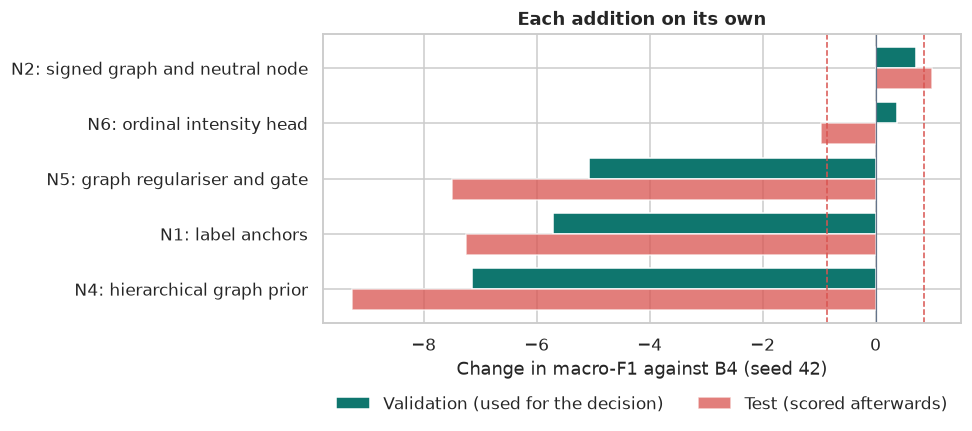

In [8]:
order = ["N2", "N6", "N5", "N1", "N4"]
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(order)); h = 0.38
dv = [S[SINGLE[n]]["val_f1"] - S[B4]["val_f1"] for n in order]
dt = [S[SINGLE[n]]["test_f1"] - S[B4]["test_f1"] for n in order]
ax.barh(y - h / 2, dv, h, color=TEAL, label="Validation (used for the decision)")
ax.barh(y + h / 2, dt, h, color=CORAL, alpha=0.75, label="Test (scored afterwards)")
ax.axvline(0, color=SLATE, lw=0.8)
for v in (-noise, noise):
    ax.axvline(v, color=CORAL, ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels([f"{n}: {MEANING[n]}" for n in order]); ax.invert_yaxis()
ax.set(xlabel="Change in macro-F1 against B4 (seed 42)", title="Each addition on its own")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.show()

In [9]:
res = {n: verdict(S[SINGLE[n]]["val_f1"] - S[B4]["val_f1"]) for n in SINGLE}
hurt = [n for n, v in res.items() if v == "hurts"]
neutral = [n for n, v in res.items() if v == "neutral"]
help_ = [n for n, v in res.items() if v == "helps"]
say(f'''**Interpretation.** Dashed lines mark the noise band of ±{noise:.2f}. Under the rule, the following verdicts follow from the validation scores: {", ".join(f"{n} {v}" for n, v in res.items())}.

- **Hurt:** {", ".join(hurt) or "none"}. These lost between {min(S[SINGLE[n]]["val_f1"] - S[B4]["val_f1"] for n in hurt):.1f} and {max(S[SINGLE[n]]["val_f1"] - S[B4]["val_f1"] for n in hurt):.1f} points on validation, and the test split shows the same direction, with losses of {abs(min(S[SINGLE[n]]["test_f1"] - S[B4]["test_f1"] for n in hurt)):.1f} to {abs(max(S[SINGLE[n]]["test_f1"] - S[B4]["test_f1"] for n in hurt)):.1f} points. Their training curves were still rising at the last epoch, so these results indicate slower learning within the available budget and do not prove that the additions are useless.
- **Neutral:** {", ".join(neutral) or "none"}. N2 is the closest to a gain ({S[SINGLE["N2"]]["val_f1"] - S[B4]["val_f1"]:+.2f} on validation and {S[SINGLE["N2"]]["test_f1"] - S[B4]["test_f1"]:+.2f} on test) but lies inside the band, so it is dropped by the rule. N6 is also neutral and is retained through the stated exception.
- **Retained for the full-data model:** N6 only.''')

**Interpretation.** Dashed lines mark the noise band of ±0.86. Under the rule, the following verdicts follow from the validation scores: N1 hurts, N2 neutral, N4 hurts, N5 hurts, N6 neutral.

- **Hurt:** N1, N4, N5. These lost between -7.1 and -5.1 points on validation, and the test split shows the same direction, with losses of 9.3 to 7.2 points. Their training curves were still rising at the last epoch, so these results indicate slower learning within the available budget and do not prove that the additions are useless.
- **Neutral:** N2, N6. N2 is the closest to a gain (+0.71 on validation and +1.00 on test) but lies inside the band, so it is dropped by the rule. N6 is also neutral and is retained through the stated exception.
- **Retained for the full-data model:** N6 only.

### 4.1 Per-language scores in the subset

In [10]:
langs = sorted(S[B4]["val_lang"])
SHOW = [("B2 (linear head)", "b2_subset"), ("B4", B4)] + [(f"B4 + {n}", r) for n, r in SINGLE.items()] + \
       [("N1 + N2", "s1_subset"), ("N1 + N2 + N4 + N5", "s2_subset"), ("all five", "final_subset_s42")]
for split, title in (("val", "Validation (tuned thresholds)"), ("test", "Test")):
    t = pd.DataFrame({name: {**{l: S[r][f"{split}_lang"][l] for l in langs}, "mean": S[r][f"{split}_f1"]} for name, r in SHOW}).T
    t.index.name = title
    display(t.round(2))

| Validation (tuned thresholds) | eng | hau | mar | ukr | mean |
|---|---|---|---|---|---|
| B2 (linear head) | 68.84 | 65.26 | 88.68 | 54.44 | 69.30 |
| B4 | 68.44 | 60.93 | 88.19 | 50.65 | 67.05 |
| B4 + N1 | 65.30 | 50.98 | 81.13 | 47.94 | 61.34 |
| B4 + N2 | 68.44 | 64.16 | 88.07 | 50.39 | 67.76 |
| B4 + N4 | 60.66 | 48.23 | 79.77 | 51.00 | 59.91 |
| B4 + N5 | 66.63 | 52.90 | 76.65 | 51.72 | 61.97 |
| B4 + N6 | 65.08 | 65.49 | 86.86 | 52.27 | 67.43 |
| N1 + N2 | 65.88 | 51.51 | 80.81 | 47.54 | 61.43 |
| N1 + N2 + N4 + N5 | 69.63 | 61.68 | 82.43 | 53.30 | 66.76 |
| all five | 68.47 | 61.02 | 81.88 | 52.76 | 66.03 |

| Test | eng | hau | mar | ukr | mean |
|---|---|---|---|---|---|
| B2 (linear head) | 67.04 | 60.81 | 81.90 | 52.10 | 65.46 |
| B4 | 65.24 | 58.02 | 80.04 | 57.00 | 65.07 |
| B4 + N1 | 61.05 | 48.83 | 73.40 | 48.03 | 57.83 |
| B4 + N2 | 66.98 | 60.31 | 81.53 | 55.49 | 66.08 |
| B4 + N4 | 56.24 | 45.71 | 70.82 | 50.42 | 55.80 |
| B4 + N5 | 64.06 | 48.84 | 67.26 | 50.13 | 57.57 |
| B4 + N6 | 63.07 | 59.53 | 80.08 | 53.77 | 64.11 |
| N1 + N2 | 61.44 | 49.91 | 72.80 | 46.35 | 57.63 |
| N1 + N2 + N4 + N5 | 65.89 | 56.32 | 76.48 | 53.83 | 63.13 |
| all five | 65.61 | 58.61 | 76.32 | 52.94 | 63.37 |

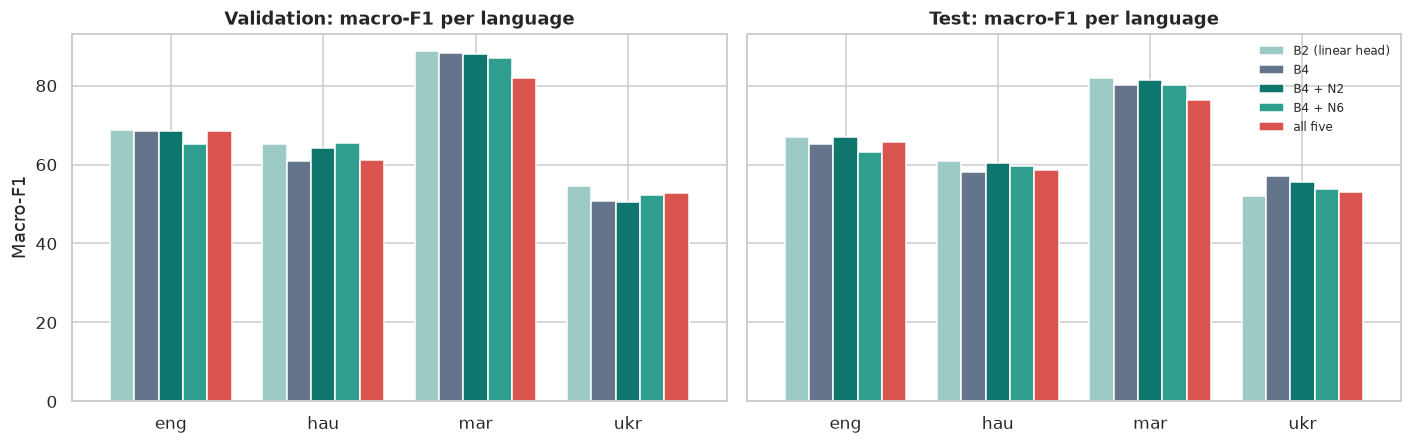

**Interpretation.** Marathi scores highest and Ukrainian lowest in both splits, so the language effect is larger than the effect of any single addition. The losses of N1, N4 and N5 are concentrated in Hausa and Marathi. N2 and N6 both improve Hausa on validation, which shows that an addition that is neutral on average can still help one language.

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, split, title in zip(axes, ("val", "test"), ("Validation", "Test")):
    data = pd.DataFrame({name: {l: S[r][f"{split}_lang"][l] for l in langs} for name, r in SHOW if name in ("B2 (linear head)", "B4", "B4 + N2", "B4 + N6", "all five")})
    data.plot.bar(ax=ax, width=0.8, color=[MINT, SLATE, TEAL, "#2F9E8F", CORAL])
    ax.set(title=f"{title}: macro-F1 per language", xlabel="", ylabel="Macro-F1")
    ax.tick_params(axis="x", rotation=0)
axes[1].legend(frameon=False, fontsize=8)
axes[0].get_legend().remove()
plt.show()
say('''**Interpretation.** Marathi scores highest and Ukrainian lowest in both splits, so the language effect is larger than the effect of any single addition. The losses of N1, N4 and N5 are concentrated in Hausa and Marathi. N2 and N6 both improve Hausa on validation, which shows that an addition that is neutral on average can still help one language.''')

### 4.2 Cumulative runs and seed variation

| cumulative run (seed 42) | validation | change vs B4 (val) | test | change vs B4 (test) |
|---|---|---|---|---|
| B2: linear head, no graph | 69.30 | 2.25 | 65.46 | 0.390 |
| B4 | 67.05 | 0.000 | 65.07 | 0.000 |
| + N1 + N2 | 61.43 | -5.62 | 57.63 | -7.45 |
| + N1 + N2 + N4 + N5 | 66.76 | -0.290 | 63.13 | -1.94 |
| + N6 (all five) | 66.03 | -1.02 | 63.37 | -1.70 |

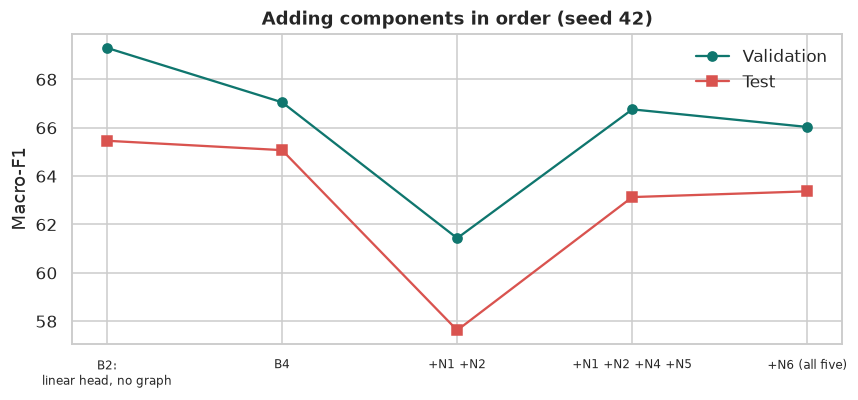

In [12]:
cum = [("B2: linear head, no graph", "b2_subset"), ("B4", B4), ("+ N1 + N2", "s1_subset"),
       ("+ N1 + N2 + N4 + N5", "s2_subset"), ("+ N6 (all five)", "final_subset_s42")]
c = pd.DataFrame({n: {"validation": S[r]["val_f1"], "change vs B4 (val)": S[r]["val_f1"] - S[B4]["val_f1"],
                      "test": S[r]["test_f1"], "change vs B4 (test)": S[r]["test_f1"] - S[B4]["test_f1"]} for n, r in cum}).T
c.index.name = "cumulative run (seed 42)"
display(c.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = range(len(cum))
ax.plot(x, [S[r]["val_f1"] for _, r in cum], marker="o", color=TEAL, label="Validation")
ax.plot(x, [S[r]["test_f1"] for _, r in cum], marker="s", color=CORAL, label="Test")
ax.set_xticks(list(x)); ax.set_xticklabels([n.replace(": ", ":\n").replace("+ ", "+") for n, _ in cum], fontsize=8)
ax.set(ylabel="Macro-F1", title="Adding components in order (seed 42)"); ax.legend(frameon=False)
plt.show()

In [13]:
GROUPS = {"B4": ("b4_subset_s42", "b4_subset_s1", "b4_subset_s2"),
          "all five additions (with quota)": ("final_subset_s42", "final_subset_s1", "final_subset_s2"),
          "all five additions (no quota)": ("nq_subset_s42", "nq_subset_s1", "nq_subset_s2")}
seeds = {}
for name, runs in GROUPS.items():
    v = [S[r]["val_f1"] for r in runs]; t = [S[r]["test_f1"] for r in runs]
    seeds[name] = {"validation mean": np.mean(v), "validation std": np.std(v, ddof=1), "test mean": np.mean(t), "test std": np.std(t, ddof=1),
                   "validation seeds": ", ".join(f"{x:.2f}" for x in v)}
seeds = pd.DataFrame(seeds).T
seeds.index.name = "three seeds (42, 1, 2)"
display(seeds.assign(**{c: seeds[c].astype(float).round(2) for c in seeds.columns if c != "validation seeds"}))
gap = seeds.loc["all five additions (with quota)", "validation mean"] - seeds.loc["B4", "validation mean"]
say(f'''**Interpretation.** Adding N1 and N2 together lowers validation macro-F1 by {S[B4]["val_f1"] - S["s1_subset"]["val_f1"]:.1f} points, yet adding N4 and N5 on top recovers most of it ({S["s2_subset"]["val_f1"] - S["s1_subset"]["val_f1"]:+.1f}), so the additions interact and single-addition results do not predict the combination. Over three seeds the model with all additions differs from B4 by {gap:+.2f} points on validation, within the project's limit of two points. The linear head B2 scores {S["b2_subset"]["val_f1"] - S[B4]["val_f1"]:+.2f} against B4 on validation and {S["b2_subset"]["test_f1"] - S[B4]["test_f1"]:+.2f} on test, so on these four languages the graph head adds little. The subset is easier than the full task (its four languages average above the 28-language mean), and it contains only one language without intensity labels, so it cannot show how the additions behave on the weakest languages.''')

| three seeds (42, 1, 2) | validation mean | validation std | test mean | test std | validation seeds |
|---|---|---|---|---|---|
| B4 | 67.23 | 0.860 | 64.53 | 0.540 | 67.05, 66.46, 68.16 |
| all five additions (with quota) | 66.97 | 0.810 | 63.81 | 0.390 | 66.03, 67.39, 67.47 |
| all five additions (no quota) | 66.67 | 1.13 | 63.62 | 0.420 | 67.26, 65.36, 67.38 |

**Interpretation.** Adding N1 and N2 together lowers validation macro-F1 by 5.6 points, yet adding N4 and N5 on top recovers most of it (+5.3), so the additions interact and single-addition results do not predict the combination. Over three seeds the model with all additions differs from B4 by -0.26 points on validation, within the project's limit of two points. The linear head B2 scores +2.25 against B4 on validation and +0.39 on test, so on these four languages the graph head adds little. The subset is easier than the full task (its four languages average above the 28-language mean), and it contains only one language without intensity labels, so it cannot show how the additions behave on the weakest languages.

## 5. Full-data comparison

The full-data runs use all 28 languages. `final_full` contains all five additions and the intensity quota, and `final_full_noquota` is identical except that the quota is removed. The models `b4_full` and `best_full` (B4 plus N6, no quota) are shown as references. All scores are on the official test split, and each model was scored once.

In [14]:
FULL_SET = [r for r in ("b4_full", "final_full", "final_full_noquota", "best_full") if r in S]
LABEL = {"b4_full": "B4", "final_full": "All additions (quota)", "final_full_noquota": "All additions (no quota)", "best_full": "B4 + N6 (no quota)"}
has_int = S["final_full_noquota"]["has_int"]
no_int = [l for l in S["final_full_noquota"]["test_lang"] if l not in has_int]

tab = {}
for r in FULL_SET:
    tl = S[r]["test_lang"]
    tab[LABEL[r]] = {"validation": S[r]["val_f1"], "test, 28 languages": S[r]["test_f1"],
                     f"test, {len(has_int)} with intensity labels": np.mean([tl[l] for l in has_int]),
                     f"test, {len(no_int)} without": np.mean([tl[l] for l in no_int]),
                     "Track B Pearson": S[r].get("test_pearson", np.nan)}
tab = pd.DataFrame(tab).T
tab.index.name = "model"
tab.assign(**{c: tab[c].astype(float).round(2) for c in tab.columns if c != "Track B Pearson"}).assign(**{"Track B Pearson": tab["Track B Pearson"].astype(float).round(3)})

| model | validation | test, 28 languages | test, 11 with intensity labels | test, 17 without | Track B Pearson |
|---|---|---|---|---|---|
| B4 | 54.91 | 52.54 | 62.03 | 46.41 |  |
| All additions (quota) | 49.44 | 47.58 | 60.98 | 38.91 | 0.545 |
| All additions (no quota) | 53.85 | 51.68 | 63.74 | 43.88 | 0.600 |
| B4 + N6 (no quota) | 55.89 | 53.47 | 63.04 | 47.28 | 0.574 |

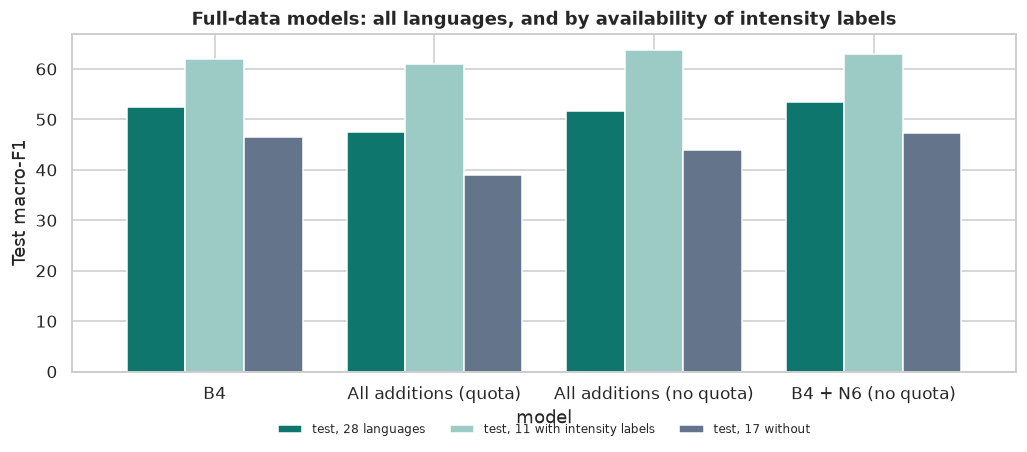

**Interpretation.** Removing the intensity quota raises the test macro-F1 from 47.58 to 51.68 (+4.10). The effect is concentrated in the languages without intensity labels, which rise from 38.91 to 43.88, whereas the languages with intensity labels change from 60.98 to 63.74. The quota gave half of every batch to the languages with intensity labels, so the other 17 received much less training. Intensity (Track B Pearson) also improves, from 0.545 to 0.600. One caveat applies: `final_full` trained for 5 epochs and `final_full_noquota` for 8, so part of the gain may come from the additional epochs.

In [15]:
cols = [c for c in tab.columns if c.startswith("test,")]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
tab[cols].plot.bar(ax=ax, color=[TEAL, MINT, SLATE], width=0.8)
ax.set(ylabel="Test macro-F1", title="Full-data models: all languages, and by availability of intensity labels")
ax.tick_params(axis="x", rotation=0); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=8)
plt.show()
q, nq = S["final_full"], S["final_full_noquota"]
qg = lambda s, g: np.mean([s["test_lang"][l] for l in g])
say(f'''**Interpretation.** Removing the intensity quota raises the test macro-F1 from {q["test_f1"]:.2f} to {nq["test_f1"]:.2f} ({nq["test_f1"] - q["test_f1"]:+.2f}). The effect is concentrated in the languages without intensity labels, which rise from {qg(q, no_int):.2f} to {qg(nq, no_int):.2f}, whereas the languages with intensity labels change from {qg(q, has_int):.2f} to {qg(nq, has_int):.2f}. The quota gave half of every batch to the languages with intensity labels, so the other {len(no_int)} received much less training. Intensity (Track B Pearson) also improves, from {q["test_pearson"]:.3f} to {nq["test_pearson"]:.3f}. One caveat applies: `final_full` trained for 5 epochs and `final_full_noquota` for 8, so part of the gain may come from the additional epochs.''')

### 5.1 Track A by language

| language | B4 | All additions (quota) | All additions (no quota) | B4 + N6 (no quota) | no quota − quota |
|---|---|---|---|---|---|
| hin | 78.33 | 76.38 | 83.44 | 78.22 | 7.06 |
| rus | 77.46 | 77.21 | 82.66 | 78.05 | 5.46 |
| mar | 76.74 | 76.15 | 81.54 | 78.93 | 5.39 |
| esp | 71.86 | 71.61 | 72.73 | 74.49 | 1.12 |
| ron | 69.92 | 70.77 | 72.46 | 70.87 | 1.69 |
| eng | 62.92 | 65.82 | 66.81 | 65.01 | 0.980 |
| amh | 64.57 | 61.18 | 64.06 | 63.93 | 2.89 |
| chn | 60.12 | 58.99 | 62.39 | 60.88 | 3.40 |
| deu | 59.35 | 59.10 | 61.09 | 61.28 | 1.99 |
| ukr | 58.30 | 52.11 | 58.07 | 57.82 | 5.96 |
| hau | 57.16 | 53.91 | 57.77 | 58.98 | 3.86 |
| tat | 59.89 | 40.86 | 57.51 | 63.30 | 16.65 |
| swe | 55.77 | 50.64 | 55.94 | 54.16 | 5.30 |
| pcm | 55.18 | 49.85 | 54.48 | 54.14 | 4.63 |
| arq | 49.28 | 51.88 | 52.07 | 51.11 | 0.190 |
| ptbr | 51.42 | 48.24 | 51.06 | 51.00 | 2.82 |
| ary | 46.81 | 43.56 | 45.80 | 47.41 | 2.24 |
| tir | 48.61 | 41.59 | 44.89 | 47.81 | 3.30 |
| afr | 42.63 | 47.48 | 42.95 | 43.81 | -4.54 |
| som | 45.29 | 30.33 | 40.65 | 41.78 | 10.32 |
| sun | 42.46 | 41.46 | 39.73 | 43.63 | -1.72 |
| ptmz | 43.87 | 30.97 | 39.32 | 43.47 | 8.35 |
| orm | 48.10 | 33.69 | 37.93 | 48.80 | 4.24 |
| kin | 33.89 | 23.38 | 35.59 | 38.26 | 12.20 |
| ibo | 44.81 | 29.29 | 35.54 | 47.57 | 6.25 |
| swa | 30.43 | 24.21 | 27.39 | 29.30 | 3.18 |
| yor | 20.91 | 13.92 | 15.04 | 23.60 | 1.12 |
| vmw | 15.16 | 7.63 | 8.19 | 19.54 | 0.550 |

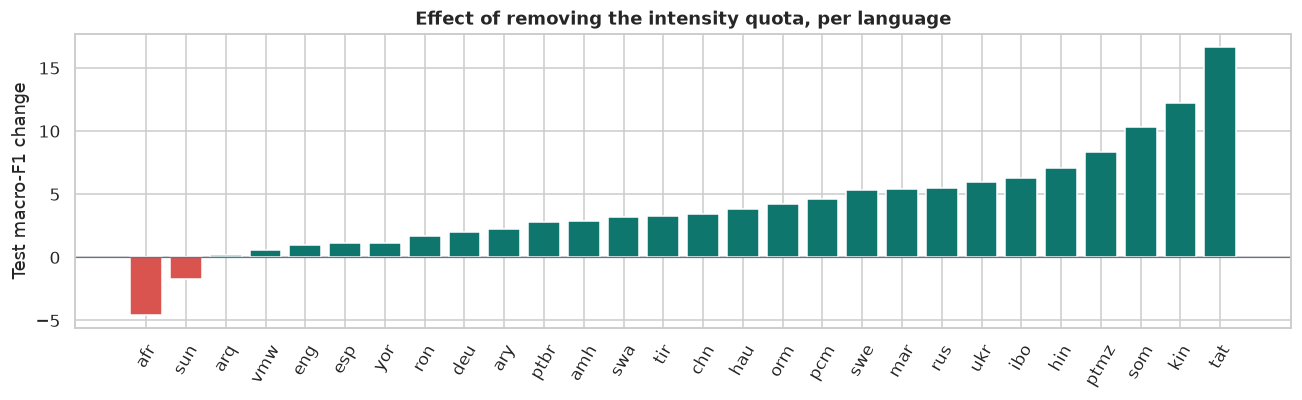

**Interpretation.** Removing the quota helps 26 of 28 languages. The largest gains are in tat (+16.6), kin (+12.2), som (+10.3), and the only declines are in afr (-4.5), sun (-1.7). Of the five largest gains, 5 are languages without intensity labels, which is consistent with the quota having taken training time from them.

In [16]:
lang_tab = pd.DataFrame({LABEL[r]: S[r]["test_lang"] for r in FULL_SET})
lang_tab["no quota − quota"] = lang_tab[LABEL["final_full_noquota"]] - lang_tab[LABEL["final_full"]]
lang_tab = lang_tab.sort_values(LABEL["final_full_noquota"], ascending=False)
lang_tab.index.name = "language"
display(lang_tab.round(2))

d = lang_tab["no quota − quota"].sort_values()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(d.index, d.values, color=[CORAL if v < 0 else TEAL for v in d.values])
ax.axhline(0, color=SLATE, lw=0.8); ax.tick_params(axis="x", rotation=60)
ax.set(ylabel="Test macro-F1 change", title="Effect of removing the intensity quota, per language")
plt.show()
say(f'''**Interpretation.** Removing the quota helps {int((d > 0).sum())} of {len(d)} languages. The largest gains are in {", ".join(f"{l} ({v:+.1f})" for l, v in d.tail(3)[::-1].items())}, and the only declines are in {", ".join(f"{l} ({v:+.1f})" for l, v in d[d < 0].items()) or "no language"}. Of the five largest gains, {sum(l in no_int for l in d.tail(5).index)} are languages without intensity labels, which is consistent with the quota having taken training time from them.''')

### 5.2 Track A by emotion

In [17]:
emo = pd.DataFrame({LABEL[r]: S[r]["emotion"] for r in FULL_SET})
emo.index.name = "emotion"
display(emo.round(2))
say(f'''**Interpretation.** Joy and sadness are the easiest emotions and disgust and fear the hardest in every model. The no-quota model is higher than the quota model for every emotion, with the largest gap for {(emo[LABEL["final_full_noquota"]] - emo[LABEL["final_full"]]).idxmax()} ({(emo[LABEL["final_full_noquota"]] - emo[LABEL["final_full"]]).max():+.1f} points).''')

| emotion | B4 | All additions (quota) | All additions (no quota) | B4 + N6 (no quota) |
|---|---|---|---|---|
| anger | 47.48 | 44.18 | 49.65 | 49.17 |
| disgust | 43.91 | 40.12 | 44.60 | 46.61 |
| fear | 47.14 | 40.05 | 45.14 | 47.13 |
| joy | 66.10 | 61.16 | 63.98 | 66.13 |
| sadness | 59.52 | 54.55 | 58.28 | 59.52 |
| surprise | 50.74 | 44.38 | 47.82 | 51.88 |

**Interpretation.** Joy and sadness are the easiest emotions and disgust and fear the hardest in every model. The no-quota model is higher than the quota model for every emotion, with the largest gap for anger (+5.5 points).

### 5.3 Track B: intensity

| language | All additions (quota) | All additions (no quota) | B4 + N6 (no quota) |
|---|---|---|---|
| rus | 0.747 | 0.860 | 0.746 |
| esp | 0.664 | 0.697 | 0.698 |
| amh | 0.584 | 0.625 | 0.603 |
| eng | 0.593 | 0.617 | 0.563 |
| ron | 0.580 | 0.603 | 0.557 |
| chn | 0.532 | 0.601 | 0.565 |
| deu | 0.551 | 0.586 | 0.579 |
| ukr | 0.505 | 0.574 | 0.545 |
| hau | 0.475 | 0.567 | 0.590 |
| ptbr | 0.460 | 0.502 | 0.503 |
| arq | 0.301 | 0.366 | 0.367 |
| mean | 0.545 | 0.600 | 0.574 |

| emotion | All additions (quota) | All additions (no quota) | B4 + N6 (no quota) |
|---|---|---|---|
| anger | 0.467 | 0.563 | 0.516 |
| disgust | 0.403 | 0.520 | 0.465 |
| fear | 0.589 | 0.626 | 0.571 |
| joy | 0.714 | 0.720 | 0.720 |
| sadness | 0.611 | 0.645 | 0.629 |
| surprise | 0.467 | 0.515 | 0.536 |

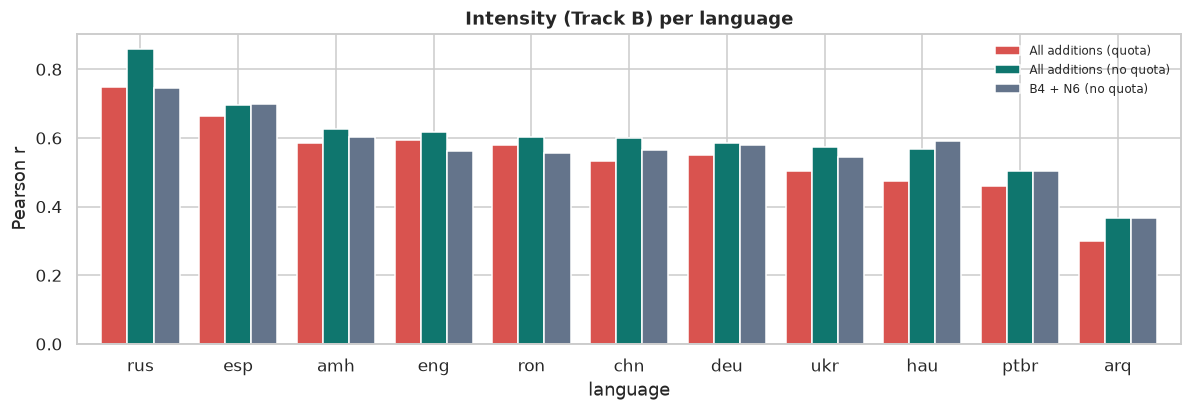

**Interpretation.** The mean Pearson correlation is 0.600 for the no-quota model and 0.545 for the quota model, a moderate correlation that is clearly above chance but leaves real error. The values range from 0.860 (rus) to 0.366 (arq). Joy is the emotion with the highest correlation. Amharic and Russian were scored on the Track A test part, because their official Track B splits overlap the Track A splits. No separate intensity baseline was run, so the benefit of the intensity head over a simpler method is not measured.

In [18]:
tb = {}
for r in FULL_SET:
    d = load(r, "test")
    if "int_pred" in d:
        tb[LABEL[r]] = E.track_b(d["intensity"], d["int_pred"], d["lang"])
tb_lang = pd.DataFrame({k: v["per_language"] for k, v in tb.items()}).sort_values(LABEL["final_full_noquota"], ascending=False)
tb_lang.loc["mean"] = [v["mean"] for v in tb.values()]
tb_lang.index.name = "language"
display(tb_lang.round(3))

tb_emo = pd.DataFrame({k: {e: np.nanmean([v["per_emotion"][l][e] for l in v["per_emotion"] if e in v["per_emotion"][l]]) for e in ("anger", "disgust", "fear", "joy", "sadness", "surprise")} for k, v in tb.items()})
tb_emo.index.name = "emotion"
display(tb_emo.round(3))

fig, ax = plt.subplots(figsize=(11, 3.9))
tb_lang.drop("mean").plot.bar(ax=ax, width=0.8, color=[CORAL, TEAL, SLATE][: tb_lang.shape[1]])
ax.set(ylabel="Pearson r", title="Intensity (Track B) per language"); ax.tick_params(axis="x", rotation=0); ax.legend(frameon=False, fontsize=8)
plt.show()
best_l = tb_lang.drop("mean")[LABEL["final_full_noquota"]].idxmax(); worst_l = tb_lang.drop("mean")[LABEL["final_full_noquota"]].idxmin()
say(f'''**Interpretation.** The mean Pearson correlation is {tb_lang.loc["mean", LABEL["final_full_noquota"]]:.3f} for the no-quota model and {tb_lang.loc["mean", LABEL["final_full"]]:.3f} for the quota model, a moderate correlation that is clearly above chance but leaves real error. The values range from {tb_lang.drop("mean")[LABEL["final_full_noquota"]].max():.3f} ({best_l}) to {tb_lang.drop("mean")[LABEL["final_full_noquota"]].min():.3f} ({worst_l}). Joy is the emotion with the highest correlation. Amharic and Russian were scored on the Track A test part, because their official Track B splits overlap the Track A splits. No separate intensity baseline was run, so the benefit of the intensity head over a simpler method is not measured.''')

### 5.4 Track C: languages never trained on

In [19]:
tc = {}
for r in FULL_SET:
    p = ROOT / "runs" / r / "predictions" / "trackc.npz"
    if p.exists():
        d = dict(np.load(p, allow_pickle=True))
        a = E.track_a(d["y"], d["pred"], d["mask"], d["lang"])
        tc[LABEL[r]] = {**{k: v * 100 for k, v in a["per_language"].items()}, "mean": a["mean"] * 100}
tc = pd.DataFrame(tc)
tc.index.name = "language"
display(tc.round(2))
say(f'''**Interpretation.** Indonesian and Javanese reach usable scores ({tc.loc["ind"].max():.1f} and {tc.loc["jav"].max():.1f} at best), whereas Xhosa and Zulu stay close to zero in every model, which brings the mean to about {tc.loc["mean"].max():.0f}. The models that keep the language-family prior (the two models with all additions) score highest here, which is the setting for which the hierarchical prior was designed. The model without it (`best_full`) is the lowest.''')

| language | All additions (quota) | All additions (no quota) | B4 + N6 (no quota) |
|---|---|---|---|
| ind | 44.31 | 48.13 | 45.78 |
| jav | 32.30 | 34.58 | 29.24 |
| xho | 5.13 | 5.79 | 3.45 |
| zul | 5.16 | 6.09 | 5.11 |
| mean | 21.72 | 23.65 | 20.90 |

**Interpretation.** Indonesian and Javanese reach usable scores (48.1 and 34.6 at best), whereas Xhosa and Zulu stay close to zero in every model, which brings the mean to about 24. The models that keep the language-family prior (the two models with all additions) score highest here, which is the setting for which the hierarchical prior was designed. The model without it (`best_full`) is the lowest.

### 5.5 Statistical comparison and quality measures

In [20]:
pairs = [("final_full_noquota", "final_full"), ("final_full_noquota", "b4_full"), ("final_full", "b4_full"), ("best_full", "final_full_noquota")]
boot = {}
for a, b in pairs:
    if a in S and b in S:
        da, db = load(a, "test"), load(b, "test")
        assert np.array_equal(da["id"], db["id"]), "the runs were not scored on the same rows"
        r = E.paired_bootstrap(da["y"], da["pred"], db["pred"], da["mask"], da["lang"])
        boot[f"{LABEL[a]} − {LABEL[b]}"] = {"difference": r["mean_diff"] * 100, "95% interval low": r["ci_low"] * 100,
                                           "95% interval high": r["ci_high"] * 100, "one-sided p": r["p_value"]}
boot = pd.DataFrame(boot).T
boot.index.name = "comparison (1,000 resamples)"
display(boot.round(3))

qual = pd.DataFrame({LABEL[r]: {"co-occurrence fidelity (lower is better)": S[r]["fidelity"], "calibration error, ECE (lower is better)": S[r]["ece"]} for r in FULL_SET}).T
qual.index.name = "model"
display(qual.round(4))
say(f'''**Interpretation.** In the bootstrap, test rows are resampled within each language 1,000 times, and a difference is considered stable when its 95% interval excludes zero. The interval of "{boot.index[0]}" ({boot.iloc[0, 1]:.2f} to {boot.iloc[0, 2]:.2f}) lies above zero. The bootstrap covers sampling of test rows only and not variation between seeds, and each full-data model has a single seed. On the quality measures, the no-quota model reproduces real emotion pairs best (fidelity {qual.loc[LABEL["final_full_noquota"]].iloc[0]:.3f}), even though its macro-F1 is lower than that of the model with only the intensity head.''')

| comparison (1,000 resamples) | difference | 95% interval low | 95% interval high | one-sided p |
|---|---|---|---|---|
| All additions (no quota) − All additions (quota) | 4.109 | 3.657 | 4.571 | 0.000 |
| All additions (no quota) − B4 | -0.858 | -1.301 | -0.371 | 1.00 |
| All additions (quota) − B4 | -4.967 | -5.442 | -4.497 | 1.00 |
| B4 + N6 (no quota) − All additions (no quota) | 1.778 | 1.283 | 2.263 | 0.000 |

| model | co-occurrence fidelity (lower is better) | calibration error, ECE (lower is better) |
|---|---|---|
| B4 | 0.403 | 0.125 |
| All additions (quota) | 0.460 | 0.157 |
| All additions (no quota) | 0.291 | 0.136 |
| B4 + N6 (no quota) | 0.335 | 0.120 |

**Interpretation.** In the bootstrap, test rows are resampled within each language 1,000 times, and a difference is considered stable when its 95% interval excludes zero. The interval of "All additions (no quota) − All additions (quota)" (3.66 to 4.57) lies above zero. The bootstrap covers sampling of test rows only and not variation between seeds, and each full-data model has a single seed. On the quality measures, the no-quota model reproduces real emotion pairs best (fidelity 0.291), even though its macro-F1 is lower than that of the model with only the intensity head.

## 6. Conclusions

In [21]:
best = max(FULL_SET, key=lambda r: S[r]["test_f1"])
say(f'''**Results from this notebook**

- **Subset experiment (four languages, 17 runs):** under the pre-committed rule, {", ".join(hurt)} hurt, {", ".join(neutral)} were neutral and {", ".join(help_) if help_ else "none"} helped. The noise band was {noise:.2f} points. N6 was retained by the stated exception.
- **Seeds:** across three seeds, B4 scores {seeds.loc["B4", "validation mean"]:.2f} ± {seeds.loc["B4", "validation std"]:.2f} on validation, and the model with all additions {seeds.loc["all five additions (with quota)", "validation mean"]:.2f} ± {seeds.loc["all five additions (with quota)", "validation std"]:.2f}.
- **Full data:** the highest test macro-F1 among the models shown is {LABEL[best]} ({S[best]["test_f1"]:.2f}). The model with all five additions scores {S["final_full"]["test_f1"]:.2f} with the intensity quota and {S["final_full_noquota"]["test_f1"]:.2f} without it.
- **Intensity and unseen languages:** the no-quota model with all additions has the highest Track B Pearson ({S["final_full_noquota"]["test_pearson"]:.3f}) and the highest Track C macro-F1 ({tc.loc["mean", LABEL["final_full_noquota"]]:.2f}).''')

**Results from this notebook**

- **Subset experiment (four languages, 17 runs):** under the pre-committed rule, N1, N4, N5 hurt, N2, N6 were neutral and none helped. The noise band was 0.86 points. N6 was retained by the stated exception.
- **Seeds:** across three seeds, B4 scores 67.23 ± 0.86 on validation, and the model with all additions 66.97 ± 0.81.
- **Full data:** the highest test macro-F1 among the models shown is B4 + N6 (no quota) (53.47). The model with all five additions scores 47.58 with the intensity quota and 51.68 without it.
- **Intensity and unseen languages:** the no-quota model with all additions has the highest Track B Pearson (0.600) and the highest Track C macro-F1 (23.65).

**What this shows**

- Most of the proposed additions did not improve macro-F1 within the available training budget, and the intensity quota had a larger effect than most architectural changes.
- The additions were not without value: the model that contains all of them leads on intensity, on unseen languages and on emotion-pair fidelity.
- The main notebook (`EmoLDGN_BRIGHTER.ipynb`) reports the selected model, B4 plus the intensity head without the quota, on the same test split.

**Limitations**

- Each full-data model has one seed, so small differences should be read with care.
- The subset contains four languages that are easier than the full set, and only one of them lacks intensity labels.
- The test scores of the earlier full-data runs were known when the selection rule was written, so the comparison is not fully blind, although the decision itself used validation data only.
- Scores are local, computed with the official metrics, and were not submitted to the leaderboard.